In [1321]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

In [1322]:
torch.manual_seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [1323]:
data = pd.read_csv('./data/processed/train.csv')

X = data.drop(columns=['LogSalePrice'])
y = data['LogSalePrice']

In [1324]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=.3, random_state=42)
X_train.shape

(1022, 196)

In [1325]:
X_train_t = torch.tensor(X_train.values, dtype=torch.float32, device=device)
X_val_t = torch.tensor(X_val.values, dtype=torch.float32, device=device)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32, device=device).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32, device=device).view(-1, 1)

X_train_t.shape, y_train_t.shape

(torch.Size([1022, 196]), torch.Size([1022, 1]))

In [1326]:
train_dataset = TensorDataset(X_train_t, y_train_t)

In [1327]:
data_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

In [1328]:
class HousePricesRegressor(nn.Module):
    def __init__(self, input, p=0.3):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input, 128),
            nn.ReLU(),
            # nn.Dropout(p=p),
            nn.Linear(128, 1)
        )
    
    def forward(self, x):
        out = self.layers(x)

        return out


model = HousePricesRegressor(X_train.shape[1])
model

HousePricesRegressor(
  (layers): Sequential(
    (0): Linear(in_features=196, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
)

In [1329]:
input = torch.rand([16, 196], dtype=torch.float32, device=device)
model(input).shape

torch.Size([16, 1])

In [1330]:
loss_model = nn.MSELoss()
opt = torch.optim.AdamW(model.parameters(), lr=0.001)
lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt,
    mode='min',
    patience=5,
)

In [1331]:
EPOCHS = 50
train_loss = []
val_loss = []
best_loss = float('inf')
count = 0
lr_list = []

for epoch in range(EPOCHS):
    model.train()
    train_loop = tqdm(data_loader, leave=False)
    for x, target in train_loop:
        # Прямой проход + расчет ошибки модели
        pred = model(x)
        loss = loss_model(pred, target)
        
        # Обратный проход
        opt.zero_grad()
        loss.backward()
        # Шаг оптимизации
        opt.step()
    
    model.eval()
    with torch.no_grad():
        train_pred = model(X_train_t)
        current_train_loss = torch.sqrt(loss_model(train_pred, y_train_t))
        train_loss.append(current_train_loss.item())
        
        val_pred = model(X_val_t)
        current_val_loss = torch.sqrt(loss_model(val_pred, y_val_t))
        val_loss.append(current_val_loss.item())
        
    lr_scheduler.step(current_val_loss)
    lr = lr_scheduler._last_lr[0]
    lr_list.append(lr)
        
    print(f'Epoch {epoch + 1}/{EPOCHS}: Train loss - {current_train_loss:.4f} | Validation loss - {current_val_loss:.4f} ')
        
    if current_val_loss < best_loss:
        best_loss = current_val_loss.item()
        count = 0
        torch.save(model.state_dict(), 'best_model.pt')
        print(f'Model saved on {epoch + 1} epoch')
        
    if count >= 10:
        print(f'Training stopped at {epoch + 1} epoch')
        break
    
    count += 1

Epoch 1/50: Train loss - 1.1447 | Validation loss - 1.1265 
Model saved on 1 epoch


Epoch 2/50: Train loss - 0.3973 | Validation loss - 0.3604 
Model saved on 2 epoch


Epoch 3/50: Train loss - 0.3245 | Validation loss - 0.3003 
Model saved on 3 epoch


Epoch 4/50: Train loss - 0.2753 | Validation loss - 0.2631 
Model saved on 4 epoch


Epoch 5/50: Train loss - 0.2405 | Validation loss - 0.2376 
Model saved on 5 epoch


...

Epoch 46/50: Train loss - 0.0747 | Validation loss - 0.1481 
Model saved on 46 epoch


Epoch 47/50: Train loss - 0.0753 | Validation loss - 0.1490 


Epoch 48/50: Train loss - 0.0757 | Validation loss - 0.1497 


Epoch 49/50: Train loss - 0.0744 | Validation loss - 0.1484 


Epoch 50/50: Train loss - 0.0742 | Validation loss - 0.1483 


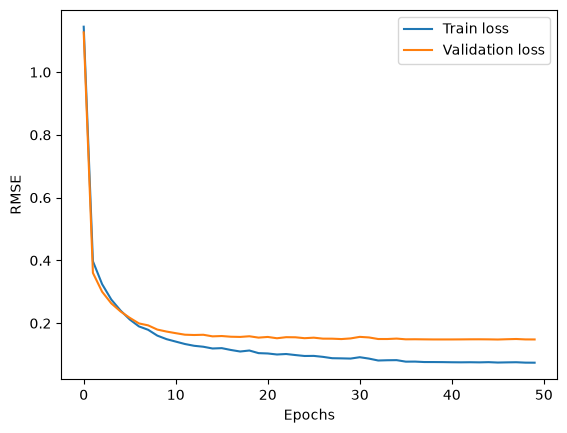

In [1332]:
sns.lineplot(train_loss, label='Train loss')
sns.lineplot(val_loss, label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('RMSE');

In [ ]:
# Предсказание на test лучшей моделью и сабмит
test_data = pd.read_csv('./data/processed/test.csv')
raw_test_df = pd.read_csv('./data/raw/test.csv')

test_data = test_data.drop(columns=['Id'])

X = torch.tensor(test_data.values, dtype=torch.float32, device=device)

model.load_state_dict(
    torch.load('best_model.pt', map_location=device)
)
model.eval()

with torch.no_grad():
    pred = model(X).squeeze(1).cpu().numpy()
    
submission = pd.DataFrame({
    'Id': raw_test_df['Id'],
    'SalePrice': np.expm1(pred)
})
submission.to_csv('./submissions/NNsubmission.csv', index=False)
# LB: 0.16147